Source [Write Context in LangGraph](https://github.com/langchain-ai/context_engineering/blob/main/context_engineering/1_write_context.ipynb)

In [1]:
from typing import TypedDict
from rich.console import Console
from rich.pretty import pprint
from dotenv import load_dotenv

In [23]:
import getpass, os
from IPython.display import Image, display
from langchain.chat_models import init_chat_model
from langgraph.graph import END, START, StateGraph
from langgraph.store.memory import InMemoryStore
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.base import BaseStore

In [3]:
load_dotenv()

console = Console()

class State(TypedDict):
    """State schema for the joke generator workflow.
    
    Attributes:
        topic: The topic for joke generation
        joke: The generated joke content
    """
    topic  : str
    joke   : str

In [15]:
def _set_env(var : str) -> None:
    """
    Set environment variable if not alread set.
    """
    if not os.environ.get(var):
        raise EnvironmentError(f"{var} not found.!!")


_set_env("GOOGLE_API_KEY")

llm = init_chat_model(
    "gemini-3.5-flash",
    model_provider = "google_genai",
    timeout        = 60,
    max_retries    = 5,
    temperature    = 0,
)

In [16]:
def generate_joke(state : State) -> dict[str, str]:
    """
    Generate a joke about the specified topic.
    
    This node reads the topic from state and generates a joke,
    then writes the joke back to state.
    
    Args:
        state: Current state containing the topic
        
    Returns:
        Dictionary with the generated joke
    """
    try:
        msg = llm.invoke(f"Write a short joke about {state['topic']}")
        return {"joke" : msg.content}
    except Exception as e:
        print(f"[GENERATION-ERROR] : {str(e)}")


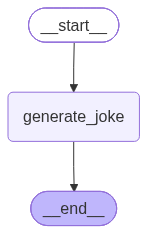

In [17]:
workflow = StateGraph(State)

workflow.add_node("generate_joke", generate_joke)

workflow.add_edge(START, "generate_joke")
workflow.add_edge("generate_joke",   END)

chain = workflow.compile()

display(Image(chain.get_graph().draw_mermaid_png()))

In [19]:
joke_generator_state = chain.invoke({"topic" : "Cats"})

console.print("\n[bold red]Joke Generator State:[/bold red]")
pprint(joke_generator_state)

Joke Generator State:

{
│   'topic': 'Cats',
│   'joke': [
│   │   {
│   │   │   'type': 'text',
│   │   │   'text': 'How do we know the Earth isn’t flat?\n\nIf it were, cats would have pushed everything off the edge by now!',
│   │   │   'extras': {
│   │   │   │   'signature': 'ErwQCrkQAWkUfROKUomYz3KokHrBVK/WiB8LpPVAsG7ke4aiABtQ2sd41GuAGcsNa6pa+Sz9+gzyJFRNpBPDd49KWMmtxWhE57SUZi/Kn+ybZmbUqq9nuvGRWpXlNpZ18+1bX8ikJmMXVJa2i0sIDB3XjaQgX+M0HFkS+5UAPbNGm5kwfkXVJ0nBEUzCI/UvnywKDTDA8Je8HRj5MOsTacPvh3O6yvFTvwQIj7zxjIiWh1HPfdwCmAnGk4VaMAt4M+/WB14bhJtnB5EePXK9FDCkV/h/pVImMp5Yr162OyOkXI6ggY8bq9I+nI9aYXaLquDaecJqPVXT9yQkkG+z4hWtbrcXWw1Twe5yoomSpWQAUcXRAFHA1k9TSX9p0Kd4AjD4rrwYkjjjOGmSuCO6ctqNEAae7k/iEQPevy4iwHvzUR7tFVoTUCqAY7r/optPTr6lMs9b7dirPc9ERljgd1N17hb7zkIYw7U3Xt6H499ipMi1olSYZvfOZ7/5EHOpvuQsu+ABFlzixRhlCCxRC1qdyhqVWtsBbPyeK3rjknHR1RYwcTvv0iKnZt4b12aXgKBtfQ6LPsb8ODXcJspcF9KGsK7c+s8lrvYHZUdtj6SgfnR6HD2408llDFJvN5AQ3rWdH7oRhHb0aTWiI/yPDlP5boJ57SajExfUXO4qkpO2aJPlfzD4PvSVuHIrTpzptvCcwrW+lgV9GuaDasRs7WH4qfztTmdJtFP8uhsiXIJgc4JQXVeUqtjduLWywr5Sfjpc4KzTecbbyBn7kEVAa3sZVlsg6cuf9FqKlFv+Yxtt9mTwzIQk5ovbieMFsgoUpkp1nlh4nZjLdW7Zrr9QBANVhPILIDYyJJJW/hDhCITHYACXykLVdpUR3sc7zePU3+gqDXH5s3YP8CbNPqXDR4AtlD7ATLrsOttJeoGwDakwwh0OUgVCYw72VYwKSWu8BRtMMG5G4Bj0Gtw3VjuHBWBb/CO3udxRdt8OVNXDkFJ81RsuFTciQ1dv6mmiNHtHFbyFz4qtzQgJd5Eohp5yY4suln7WGcVbpFhvk3aoCcbz9n3MCBCoKTV3h5FQMJK0Al8t6vwKLVEK7Z4yFZyAN95VF9+yCHlU3lctwwc4R2CwetcFqJSonAyK9BiJpWJFVTR25jHdjkivtBD8dDf8DmFuTsqJqo6v4Kx94GjhzdoE6t19Wgbcx3zpBcu/0Ql37eovZvJoJfVL3pgzNrKEPOXb34ymmz1MqJDMffMOwt6L/JbHzpHiN4d8G5Kc3q4c9LrlIqsv7QslsL5TofsNjlBRzh9RbrbxZsHgtiktybW9PM4NO8ZhIQPqtzz6tMhfNa+czF1VUHtWWkLaoCegfA7qqZ7YGPBbkiMWGxG283r0paLwq/FPyWet+ImuD58JP3XROH3bMmBPc8c4h/CJwEfmeaZ7ikS3v2aFuvYDHUvOnGBMHsjGJ53Xg4cpboJK0SyDnzK6YftQD4YG/kbMp3j/SfkeG8IwBmV8L3lbIvMuS/SMEWuaZwGy4hfcGFaRLbHRMBYr3kY8jUq8qkYsf4nNji8mp3Yq7Yt4q957IfIXQkWmeoYDEbn3lCk+Bgj/MiPPJnRjxaMqcMx2pzFJT+nTTeiqZ4UCE4E9WQ8ATATmB03BYVWddRNKpPu7XEHwuvxTy1YojXJX0xaz5HthGuLvcGHsBwpGGopUA4GQS8W0qli+JH5YW4lYZ/4jUgCBhP221/L+l6MmEpf0/5KjW8D1SJiT27S3ppXGrwAy0zkFv5QHrJlQoiKV66w0/30IdSZP6C/FRubYwEb+J8HjxhnDUgM7MNxbQ41YQziYVq5qVtU6Rj4VOM0pR8QFKynyMb+tkuLGRCpCpWJxJEe+a0WSF47nWywa/HLklH7u8XSC3loOtEc9x+xlC4JVFf2Ad2rfINqFQ3NVYpnjOQcwAg3DYe0bO6ot9nN8IK3q/wGtKtR4lDAgTF0Arqj5ufYNoMn/6+OY2WRfs982gat0U0imHs8wtiCBcTO2eR8X3GzgG+6cBQ7wzC1chamUFginkQ08u33eFbZc5eOswS2gV4P75n3GVbGfrbrl3D1iBq4wwPZk9Dfp6G5/PMfGjz5sg/Ex06nTqZ4K1lUJ/o+Eado0wRKoybwhMUhNwUSynov7QIq9kyn02xrRwZ4s4zJaVJ+mgpLgXAOHVxyG16MqYCw8NQDg646QAfF+WyqGSxctBg9lgRtv56tCsN+hOGkHitT9I4szah0WPzPg2LxMydqZMLG/sMAtK25pL/cOfs5nYs8RkbIC59FYtdxga8h/DCJBBInynmQ4EnKA6RP7/v/EJcXoOFmjr+N2pK13TJVmLztXrHSAzLKx8Qw0G2J9VwG4bX7f9UbbAQ3yEYbT3LRJ6L463tMBuvJG3hv4ErrV6FGV2VuwQ9YrZrUBU99PonCkFQkohwmMC2Fa6vCWe3vd1rC5gxlYm9Z0LzIUJMmzXj1bnHTAnIefjJarQOBxTGM7C6lmeI2S3n6tB3EFpzmJHNpwhCWfvYtGeyirtKH6Kd4ZLE1PFp1aW5Q3kzNkyzsbX8iceg7XaqsljBLWPg9EHwd69fznCqZevDdEMNwENeyq8GDGHpVhrtGafN9FPjBEjiIeb2YxGvoCE9k6hTopxKzw9EfYwqcr8t9Zk+vSKlrgh4x+V/SS4w+rnTQQvF0xZNpbgHNZw1XicPQahUu9wTH5FZRpwexylBq107dOErAn++zOQoKzWRqJRyif3Kjw2X45IhGLfLVXmlLZvDdygDOe3A1+/8p9OOqeN0ljmxHenKT05CCl/ksaCDM='
│   │   │   }
│   │   }
│   ]
}

In [21]:
store = InMemoryStore()

namespace = ("rlm", "joke_generator")

store.put(
    namespace,
    "last_joke",
    {"joke" : joke_generator_state['joke']}
)

In [22]:
stored_items = list(store.search(namespace))

console.print("\n[bold green]Stored Items in Memory:[/bold green]")
pprint(stored_items)

Stored Items in Memory:

[
│   Item(namespace=['rlm', 'joke_generator'], key='last_joke', value={'joke': [{'type': 'text', 'text': 'How do we know the Earth isn’t flat?\n\nIf it were, cats would have pushed everything off the edge by now!', 'extras': {'signature': 'ErwQCrkQAWkUfROKUomYz3KokHrBVK/WiB8LpPVAsG7ke4aiABtQ2sd41GuAGcsNa6pa+Sz9+gzyJFRNpBPDd49KWMmtxWhE57SUZi/Kn+ybZmbUqq9nuvGRWpXlNpZ18+1bX8ikJmMXVJa2i0sIDB3XjaQgX+M0HFkS+5UAPbNGm5kwfkXVJ0nBEUzCI/UvnywKDTDA8Je8HRj5MOsTacPvh3O6yvFTvwQIj7zxjIiWh1HPfdwCmAnGk4VaMAt4M+/WB14bhJtnB5EePXK9FDCkV/h/pVImMp5Yr162OyOkXI6ggY8bq9I+nI9aYXaLquDaecJqPVXT9yQkkG+z4hWtbrcXWw1Twe5yoomSpWQAUcXRAFHA1k9TSX9p0Kd4AjD4rrwYkjjjOGmSuCO6ctqNEAae7k/iEQPevy4iwHvzUR7tFVoTUCqAY7r/optPTr6lMs9b7dirPc9ERljgd1N17hb7zkIYw7U3Xt6H499ipMi1olSYZvfOZ7/5EHOpvuQsu+ABFlzixRhlCCxRC1qdyhqVWtsBbPyeK3rjknHR1RYwcTvv0iKnZt4b12aXgKBtfQ6LPsb8ODXcJspcF9KGsK7c+s8lrvYHZUdtj6SgfnR6HD2408llDFJvN5AQ3rWdH7oRhHb0aTWiI/yPDlP5boJ57SajExfUXO4qkpO2aJPlfzD4PvSVuHIrTpzptvCcwrW+lgV9GuaDasRs7WH4qfztTmdJtFP8uhsiXIJgc4JQXVeUqtjduLWywr5Sfjpc4KzTecbbyBn7kEVAa3sZVlsg6cuf9FqKlFv+Yxtt9mTwzIQk5ovbieMFsgoUpkp1nlh4nZjLdW7Zrr9QBANVhPILIDYyJJJW/hDhCITHYACXykLVdpUR3sc7zePU3+gqDXH5s3YP8CbNPqXDR4AtlD7ATLrsOttJeoGwDakwwh0OUgVCYw72VYwKSWu8BRtMMG5G4Bj0Gtw3VjuHBWBb/CO3udxRdt8OVNXDkFJ81RsuFTciQ1dv6mmiNHtHFbyFz4qtzQgJd5Eohp5yY4suln7WGcVbpFhvk3aoCcbz9n3MCBCoKTV3h5FQMJK0Al8t6vwKLVEK7Z4yFZyAN95VF9+yCHlU3lctwwc4R2CwetcFqJSonAyK9BiJpWJFVTR25jHdjkivtBD8dDf8DmFuTsqJqo6v4Kx94GjhzdoE6t19Wgbcx3zpBcu/0Ql37eovZvJoJfVL3pgzNrKEPOXb34ymmz1MqJDMffMOwt6L/JbHzpHiN4d8G5Kc3q4c9LrlIqsv7QslsL5TofsNjlBRzh9RbrbxZsHgtiktybW9PM4NO8ZhIQPqtzz6tMhfNa+czF1VUHtWWkLaoCegfA7qqZ7YGPBbkiMWGxG283r0paLwq/FPyWet+ImuD58JP3XROH3bMmBPc8c4h/CJwEfmeaZ7ikS3v2aFuvYDHUvOnGBMHsjGJ53Xg4cpboJK0SyDnzK6YftQD4YG/kbMp3j/SfkeG8IwBmV8L3lbIvMuS/SMEWuaZwGy4hfcGFaRLbHRMBYr3kY8jUq8qkYsf4nNji8mp3Yq7Yt4q957IfIXQkWmeoYDEbn3lCk+Bgj/MiPPJnRjxaMqcMx2pzFJT+nTTeiqZ4UCE4E9WQ8ATATmB03BYVWddRNKpPu7XEHwuvxTy1YojXJX0xaz5HthGuLvcGHsBwpGGopUA4GQS8W0qli+JH5YW4lYZ/4jUgCBhP221/L+l6MmEpf0/5KjW8D1SJiT27S3ppXGrwAy0zkFv5QHrJlQoiKV66w0/30IdSZP6C/FRubYwEb+J8HjxhnDUgM7MNxbQ41YQziYVq5qVtU6Rj4VOM0pR8QFKynyMb+tkuLGRCpCpWJxJEe+a0WSF47nWywa/HLklH7u8XSC3loOtEc9x+xlC4JVFf2Ad2rfINqFQ3NVYpnjOQcwAg3DYe0bO6ot9nN8IK3q/wGtKtR4lDAgTF0Arqj5ufYNoMn/6+OY2WRfs982gat0U0imHs8wtiCBcTO2eR8X3GzgG+6cBQ7wzC1chamUFginkQ08u33eFbZc5eOswS2gV4P75n3GVbGfrbrl3D1iBq4wwPZk9Dfp6G5/PMfGjz5sg/Ex06nTqZ4K1lUJ/o+Eado0wRKoybwhMUhNwUSynov7QIq9kyn02xrRwZ4s4zJaVJ+mgpLgXAOHVxyG16MqYCw8NQDg646QAfF+WyqGSxctBg9lgRtv56tCsN+hOGkHitT9I4szah0WPzPg2LxMydqZMLG/sMAtK25pL/cOfs5nYs8RkbIC59FYtdxga8h/DCJBBInynmQ4EnKA6RP7/v/EJcXoOFmjr+N2pK13TJVmLztXrHSAzLKx8Qw0G2J9VwG4bX7f9UbbAQ3yEYbT3LRJ6L463tMBuvJG3hv4ErrV6FGV2VuwQ9YrZrUBU99PonCkFQkohwmMC2Fa6vCWe3vd1rC5gxlYm9Z0LzIUJMmzXj1bnHTAnIefjJarQOBxTGM7C6lmeI2S3n6tB3EFpzmJHNpwhCWfvYtGeyirtKH6Kd4ZLE1PFp1aW5Q3kzNkyzsbX8iceg7XaqsljBLWPg9EHwd69fznCqZevDdEMNwENeyq8GDGHpVhrtGafN9FPjBEjiIeb2YxGvoCE9k6hTopxKzw9EfYwqcr8t9Zk+vSKlrgh4x+V/SS4w+rnTQQvF0xZNpbgHNZw1XicPQahUu9wTH5FZRpwexylBq107dOErAn++zOQoKzWRqJRyif3Kjw2X45IhGLfLVXmlLZvDdygDOe3A1+/8p9OOqeN0ljmxHenKT05CCl/ksaCDM='}}]}, created_at='2026-11-25T04:02:43.045726+00:00', updated_at='2026-11-25T04:02:43.045726+00:00', score=None)
]

In [24]:
checkpointer = InMemorySaver()
memory_store = InMemoryStore()



In [25]:
def generate_joke(state: State, store: BaseStore) -> dict[str, str]:
    """Generate a joke with memory awareness.
    
    This enhanced version checks for existing jokes in memory
    before generating new ones.
    
    Args:
        state: Current state containing the topic
        store: Memory store for persistent context
        
    Returns:
        Dictionary with the generated joke
    """
    # Check if there's an existing joke in memory
    existing_jokes = list(store.search(namespace))
    if existing_jokes:
        existing_joke = existing_jokes[0].value
        print(f"Existing joke: {existing_joke}")
    else:
        print("Existing joke: No existing joke")

    # Generate a new joke based on the topic
    msg = llm.invoke(f"Write a short joke about {state['topic']}")
    
    # Store the new joke in long-term memory
    store.put(namespace, "last_joke", {"joke": msg.content})

    # Return the joke to be added to state
    return {"joke": msg.content}

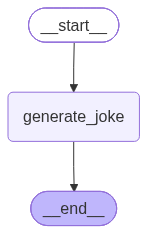

In [26]:
workflow = StateGraph(State)

workflow.add_node("generate_joke", generate_joke)


workflow.add_edge(START,  "generate_joke")
workflow.add_edge("generate_joke",    END)

chain = workflow.compile(checkpointer = checkpointer, store = memory_store)

display(Image(chain.get_graph().draw_mermaid_png()))

In [27]:
config = {"configurable": {"thread_id": "1"}}
joke_generator_state = chain.invoke({"topic": "cats"}, config)

console.print("\n[bold cyan]Workflow Result (Thread 1):[/bold cyan]")
pprint(joke_generator_state)

Existing joke: No existing joke


Workflow Result (Thread 1):

{
│   'topic': 'cats',
│   'joke': [
│   │   {
│   │   │   'type': 'text',
│   │   │   'text': 'Why was the cat sitting on the computer?\n\nTo keep an eye on the mouse!',
│   │   │   'extras': {
│   │   │   │   'signature': 'Et8NCtwNAWkUfRNEI6rhUoVWp4hTdjZKC77OclIpHaqd40Wliu6rYl+bMEvhRUZ2zisWJDNAT4s+Mo/3IZ80QVOh2r3LCezoBspL0mQ/qQm8Vb0QAAc/5GZMlRrrBgWMGhNRJggTiqt/oaGmy1W/oI4CHLPCtbNJTr92rPg0uRoDiz2BF4CUvwZcwL/18FnNUA4B2FHd59BsXj5s6RDyOLSMsEBHJSONa208IKBviVYj1DGHC9618jl8PDnlax6sc12I5Eh5XPvI5/NrbX15aYPPoPI6EzYWf3gCVfUbxT1v8ITR59Nm+SP4AIueKat/UMQRXINUOpAKXQnMFyV/1wF/oxod2b1W4MtzaPVyFlOtd2KMyVD+tZEuonmkVhufRbA3uiXuSVigLha1SgmZb9wtS4wTm58A3gaBbJ1AZHXc4zANfnbV9wjec0y/tLHr7Nc6pOtR8X5ruA66DrESxh6FBqfYbQfgBbkJDEhoGEC7kQtzkrg8vlEJK08ZKuouNl+W9OeTALvDoG75u9/wwuF2jFpjcrJcXl1ICJxrX1/1xLVKH5nM2W8WlJ+n0DG5fLUj/llayxqC9DS3dEWyw1qPmKc/Utya+zY+EwxmoHtO6XuOprrmjyqVGhA3kTASMVrAJLbNhhjaDuv+N2eLPf2WWEL2iDKBRStInY/rEc9XUr4ywrd64XKXl0bKRy3l+yNj+1db6RO+RQCkOz9v8scqqMpQA1/H+4rhKKhh3dF/FPR77CCe/edja19Mq5TEalWJRGSwRWHbsE2ggwxb6Z4kv4xyRhQSvTbAEeY4+UloBEA8oCeXfOh6UBrT1cnxzD/4qa4DNzuiphAcX+ljtiiSfeJ2iKrmXkuWkgSwR45L23wn0Q5tXhcERDr/jW/iaCFcICRUFx78fgxJcaLx+3nLTUyPXYiYjx0eSEeuGXLZiPGgTUmtBpJTBlqTIWPwhLlDu1CYdu1SYUTyMAIOzCLMrBRl+F2CjrBJKWI8xD9xTD7Mekvz01mcF3X5mUUMzZy2nGOeFXHQdVO9f5DtM5u8naSM1q9RBKv2w4q4DGiHsohC6ynmy7VtYQBJgGLwg/1y+zFPFzxGPODLNK1IIg0/2Wnb7j792pZACqvK2FGM5M+BaWjPUllonYiMZEiz4c74Tua3zcx+ew2WDZtf52W6XzEdyyEk/OfrDJkyAHZuocHcCExedyhFhbWYFJ6UBk4X9G5CMJn2lvgsrsjnz7iV7XfB+/Zk1Kgwfo5I8M3vURQFT8sxkvlZkYH70C0ObntwzwqhO1I6WTI7Q1i89qYpEuv66JpSy+/w7lg694SiHZe0TGGo/wmoSK85T6mYAHFrSDWw8S3Dda4miG5J0zByOGkMTn0FzpYc3hgqglUNKVFH2FFIC6XP8+ZGdgYsohr2JPpZvkwnICyj8LOxYEtkzx8FnPO6e1LFpuWSpTfw0KIwxwPcZqoXmMi0Bt7Afnw9MS/vYbNDN55BeHMQ+3lLCjUyd9IkLrYxJ2ywZ9MhcD+wze46ZfH2RFTIU5H7knATH11m2ZJ3HIyPFTmNPxzJSCkpp8N2RNomCehQxfXEraRPJ3F9bnSnRcv3eJ0xEjrTAP12SVdyAq2T5cSuKCq0QhBSkJK68Tz5kitQeRG7GkW5i8RYA0E8R7Nl5XmQbwP4EFf70YMWwQdGb6tngoBTc8P611aepIIPrrw3W+wSVpeYHnYXX8DVN6Qi9q/05j/hMW5e4S5NF4fjx5USdcUIdf0DOR0bXW1ZRt2KMwv7M6NYKo0C6N/3tqaPviR6LT9OQTPnOJM6+VBB3WpmOOJdHD1OUttnJ60hcGmV8Gd5FN+nyjEfzW87uOsWMpUy3UReKS5fB5l6SAOf4EsI7l6IaO4LnS3JSKnnEar4OmcwlmHLj4bevUl+jyVXK6PGHbPiBVEmi3s6tGJbftTzOWVF4X5ixknhubL/hvtfSA25WqNGQk2Po5jZ5Jo0oixw3I+p1zM6gNT1npSwkyyeJh/Cq+HFlHXwLZpq/3eA8qQttqPWXF+EWPAUA0GCBexwsmeq8pbKtqmCrVgO+kgHsm2XVqWGR3PkhK+Wv23hJFHAyHK2/kfCHgS0A/OMV1g6DMgpFsCWXaGxOU5WVY6EBNWqBEB7wBQ/V9V737/m5nhtFOoH/Z4u9swNUx0AhVRBRT33Y/RmFKwWrNUaRLwPR8UD4levmZEFCt10ISlyuFTZvkN3SdhTjly6ZaqhC8ybIYkpli2zbTR7jGLWP1pFLJvyv8vj5aryBvCkE1MOIGjaeEoPAhsVjVyux/+JLx+iH4ffGlBhzFaQlmorUbO2A/Nsgq7LtIP992WA3bn/WZiQjA=='
│   │   │   }
│   │   }
│   ]
}

In [29]:
latest_state = chain.get_state(config)

console.print("\n[bold magenta]Latest Graph State:[/bold magenta]")
pprint(latest_state)

Latest Graph State:

StateSnapshot(
│   values={
│   │   'topic': 'cats',
│   │   'joke': [
│   │   │   {
│   │   │   │   'type': 'text',
│   │   │   │   'text': 'Why was the cat sitting on the computer?\n\nTo keep an eye on the mouse!',
│   │   │   │   'extras': {
│   │   │   │   │   'signature': 'Et8NCtwNAWkUfRNEI6rhUoVWp4hTdjZKC77OclIpHaqd40Wliu6rYl+bMEvhRUZ2zisWJDNAT4s+Mo/3IZ80QVOh2r3LCezoBspL0mQ/qQm8Vb0QAAc/5GZMlRrrBgWMGhNRJggTiqt/oaGmy1W/oI4CHLPCtbNJTr92rPg0uRoDiz2BF4CUvwZcwL/18FnNUA4B2FHd59BsXj5s6RDyOLSMsEBHJSONa208IKBviVYj1DGHC9618jl8PDnlax6sc12I5Eh5XPvI5/NrbX15aYPPoPI6EzYWf3gCVfUbxT1v8ITR59Nm+SP4AIueKat/UMQRXINUOpAKXQnMFyV/1wF/oxod2b1W4MtzaPVyFlOtd2KMyVD+tZEuonmkVhufRbA3uiXuSVigLha1SgmZb9wtS4wTm58A3gaBbJ1AZHXc4zANfnbV9wjec0y/tLHr7Nc6pOtR8X5ruA66DrESxh6FBqfYbQfgBbkJDEhoGEC7kQtzkrg8vlEJK08ZKuouNl+W9OeTALvDoG75u9/wwuF2jFpjcrJcXl1ICJxrX1/1xLVKH5nM2W8WlJ+n0DG5fLUj/llayxqC9DS3dEWyw1qPmKc/Utya+zY+EwxmoHtO6XuOprrmjyqVGhA3kTASMVrAJLbNhhjaDuv+N2eLPf2WWEL2iDKBRStInY/rEc9XUr4ywrd64XKXl0bKRy3l+yNj+1db6RO+RQCkOz9v8scqqMpQA1/H+4rhKKhh3dF/FPR77CCe/edja19Mq5TEalWJRGSwRWHbsE2ggwxb6Z4kv4xyRhQSvTbAEeY4+UloBEA8oCeXfOh6UBrT1cnxzD/4qa4DNzuiphAcX+ljtiiSfeJ2iKrmXkuWkgSwR45L23wn0Q5tXhcERDr/jW/iaCFcICRUFx78fgxJcaLx+3nLTUyPXYiYjx0eSEeuGXLZiPGgTUmtBpJTBlqTIWPwhLlDu1CYdu1SYUTyMAIOzCLMrBRl+F2CjrBJKWI8xD9xTD7Mekvz01mcF3X5mUUMzZy2nGOeFXHQdVO9f5DtM5u8naSM1q9RBKv2w4q4DGiHsohC6ynmy7VtYQBJgGLwg/1y+zFPFzxGPODLNK1IIg0/2Wnb7j792pZACqvK2FGM5M+BaWjPUllonYiMZEiz4c74Tua3zcx+ew2WDZtf52W6XzEdyyEk/OfrDJkyAHZuocHcCExedyhFhbWYFJ6UBk4X9G5CMJn2lvgsrsjnz7iV7XfB+/Zk1Kgwfo5I8M3vURQFT8sxkvlZkYH70C0ObntwzwqhO1I6WTI7Q1i89qYpEuv66JpSy+/w7lg694SiHZe0TGGo/wmoSK85T6mYAHFrSDWw8S3Dda4miG5J0zByOGkMTn0FzpYc3hgqglUNKVFH2FFIC6XP8+ZGdgYsohr2JPpZvkwnICyj8LOxYEtkzx8FnPO6e1LFpuWSpTfw0KIwxwPcZqoXmMi0Bt7Afnw9MS/vYbNDN55BeHMQ+3lLCjUyd9IkLrYxJ2ywZ9MhcD+wze46ZfH2RFTIU5H7knATH11m2ZJ3HIyPFTmNPxzJSCkpp8N2RNomCehQxfXEraRPJ3F9bnSnRcv3eJ0xEjrTAP12SVdyAq2T5cSuKCq0QhBSkJK68Tz5kitQeRG7GkW5i8RYA0E8R7Nl5XmQbwP4EFf70YMWwQdGb6tngoBTc8P611aepIIPrrw3W+wSVpeYHnYXX8DVN6Qi9q/05j/hMW5e4S5NF4fjx5USdcUIdf0DOR0bXW1ZRt2KMwv7M6NYKo0C6N/3tqaPviR6LT9OQTPnOJM6+VBB3WpmOOJdHD1OUttnJ60hcGmV8Gd5FN+nyjEfzW87uOsWMpUy3UReKS5fB5l6SAOf4EsI7l6IaO4LnS3JSKnnEar4OmcwlmHLj4bevUl+jyVXK6PGHbPiBVEmi3s6tGJbftTzOWVF4X5ixknhubL/hvtfSA25WqNGQk2Po5jZ5Jo0oixw3I+p1zM6gNT1npSwkyyeJh/Cq+HFlHXwLZpq/3eA8qQttqPWXF+EWPAUA0GCBexwsmeq8pbKtqmCrVgO+kgHsm2XVqWGR3PkhK+Wv23hJFHAyHK2/kfCHgS0A/OMV1g6DMgpFsCWXaGxOU5WVY6EBNWqBEB7wBQ/V9V737/m5nhtFOoH/Z4u9swNUx0AhVRBRT33Y/RmFKwWrNUaRLwPR8UD4levmZEFCt10ISlyuFTZvkN3SdhTjly6ZaqhC8ybIYkpli2zbTR7jGLWP1pFLJvyv8vj5aryBvCkE1MOIGjaeEoPAhsVjVyux/+JLx+iH4ffGlBhzFaQlmorUbO2A/Nsgq7LtIP992WA3bn/WZiQjA=='
│   │   │   │   }
│   │   │   }
│   │   ]
│   },
│   next=(),
│   config={
│   │   'configurable': {
│   │   │   'thread_id': '1',
│   │   │   'checkpoint_ns': '',
│   │   │   'checkpoint_id': '1f1e885d-4f23-6ce3-8001-e7756b02e031'
│   │   }
│   },
│   metadata={'source': 'loop', 'step': 1, 'parents': {}},
│   created_at='2026-11-25T04:08:12.613552+00:00',
│   parent_config={
│   │   'configurable': {
│   │   │   'thread_id': '1',
│   │   │   'checkpoint_ns': '',
│   │   │   'checkpoint_id': '1f1e885d-10f9-6b23-8000-cb6e9be992bb'
│   │   }
│   },
│   tasks=(),
│   interrupts=()
)

In [30]:
config = {"configurable": {"thread_id": "2"}}
joke_generator_state = chain.invoke({"topic": "cats"}, config)

console.print("\n[bold yellow]Workflow Result (Thread 2):[/bold yellow]")
pprint(joke_generator_state)

Existing joke: {'joke': [{'type': 'text', 'text': 'Why was the cat sitting on the computer?\n\nTo keep an eye on the mouse!', 'extras': {'signature': 'Et8NCtwNAWkUfRNEI6rhUoVWp4hTdjZKC77OclIpHaqd40Wliu6rYl+bMEvhRUZ2zisWJDNAT4s+Mo/3IZ80QVOh2r3LCezoBspL0mQ/qQm8Vb0QAAc/5GZMlRrrBgWMGhNRJggTiqt/oaGmy1W/oI4CHLPCtbNJTr92rPg0uRoDiz2BF4CUvwZcwL/18FnNUA4B2FHd59BsXj5s6RDyOLSMsEBHJSONa208IKBviVYj1DGHC9618jl8PDnlax6sc12I5Eh5XPvI5/NrbX15aYPPoPI6EzYWf3gCVfUbxT1v8ITR59Nm+SP4AIueKat/UMQRXINUOpAKXQnMFyV/1wF/oxod2b1W4MtzaPVyFlOtd2KMyVD+tZEuonmkVhufRbA3uiXuSVigLha1SgmZb9wtS4wTm58A3gaBbJ1AZHXc4zANfnbV9wjec0y/tLHr7Nc6pOtR8X5ruA66DrESxh6FBqfYbQfgBbkJDEhoGEC7kQtzkrg8vlEJK08ZKuouNl+W9OeTALvDoG75u9/wwuF2jFpjcrJcXl1ICJxrX1/1xLVKH5nM2W8WlJ+n0DG5fLUj/llayxqC9DS3dEWyw1qPmKc/Utya+zY+EwxmoHtO6XuOprrmjyqVGhA3kTASMVrAJLbNhhjaDuv+N2eLPf2WWEL2iDKBRStInY/rEc9XUr4ywrd64XKXl0bKRy3l+yNj+1db6RO+RQCkOz9v8scqqMpQA1/H+4rhKKhh3dF/FPR77CCe/edja19Mq5TEalWJRGSwRWHbsE2ggwxb6Z4kv4xyRhQSvTbAEeY4+UloBEA8oCeXfOh6UBrT1cnxzD/4qa4DNzuiphAcX

Workflow Result (Thread 2):

{
│   'topic': 'cats',
│   'joke': [
│   │   {
│   │   │   'type': 'text',
│   │   │   'text': 'Why was the cat sitting on the computer?\n\nTo keep an eye on the mouse!',
│   │   │   'extras': {
│   │   │   │   'signature': 'Ev8NCvwNAWkUfRNQfLV0tn9XTdv01Xe4q4/83h/lweLt7Acg7yU/4cmivpmgYX80CvvmDmrJGZnHolHWdHjAhFULNTW0Sis+PscihDarUZweoCrycRP73tO9FLaEsOQJtYNJL1u3lR51X9zs8cMQCadwtyr0B4syJdMS3Gi/I+UzTvSy/l/6qH9KPmbLbd9AsF4c/YJDIa/V/tBp6ac6YG2CwmQG/cfIrhGrdXeYQ8G5IbGf21fVvLCxK4jUyTb8/PlfKZnlDuhGd+rAPDQOxV4VFoAmh3kPCq71dMwGmPYJKAligt1n3rziBLU2laEnFwXthZQ0kLyGx39M2PAyJVsCzgY86VTsDpUp9289q4+kuYl2z2axlzLT+ZjjVwEIsLzMIGPOrmnkxdn0DhGiHp7rl43wOLArgpZipevUsZAwhH+bPc5DhkImBqihgJhrzANlSgxge9vkILKJSPli7mHq/nXvkBNyYfepyCwMi9xDAC675H+QurhjY/GNEKT5QEIwlw+eVzc6GQf3pmoakn9Q+T8kRmkSV7gi/A6cBUhH16qkIwL5mDruhsPs18zv85KvZiMEPSdVm5ThVcPS5ZrHb7waybjuboUBbQ9IiP5FG31SuzRkRQpFmDZyknziGzKUtWgInIzuazXG2l6BdhMGMFRCeaKegE2i2ZryeoDep0PVGZCPhNwSQ6oiCxLzzuZZz7tvjk4ijZpPEBz0kwDg9bvKR1TbWq3zDEBBmCz3wuRpDjtmvcYM4D/FRxNkxOJw4EHErSUS/Xb9dG6PKRkS1mvKovw3O/2CLaUdiBl2f41mL+4THPzHFhYpyDozFdZV6Lx5/1lteGioMwFaYdhmP7GKlO8CcM1sSqr3sic9cBZr3mQAAX9b0amuuWFXQ7dtWvM61RnnyWOvId4Nimw3tQClkVd+a9m6AlWjhkZa+w9sjZtKjDlmT3qWfQUfqgvDNaDlWrWrc0pXRHvP7Out752IK9nPBgQVuC50KDmYe2Pk32mX3FFIHN6z/Wp9im4YGrUl1YMRyIawGaULAKIqNmMleoK/gnuzjz0Mq8tJLEEEJpQFUXxbz6tCXPUrk43GhX+wlAIUQkdom/m/YcE/rreB0vHMIY1njO0wwnDgCcMHIZvG7qkcE5ONH07aeb3pcf1zQqqhcq8w9N9RsEo3mKPo/x/xrFxOZZXMO6ubSdfvYLHEiZStt5sMTWFA8GBRVMg5Qqyc6Jn/s5ZfWA4o/aZbVhPiS8djTRwRQATuv2M+ue9TPEkCGLbsbHqiIz1xAHOEocPWnY7JxDbblIHJCNVsWvx61x/wf48mSvphpZ/LdPj1a9Km+4wIefs4NqjgfolzvkOVtzg/tY9q2YTT1ztpRGZIVbdsDo+Xd2Qy3FpRtbtSDRnsm/V3NKXncBK+kuD8CvDWf9OCeQus2vo38El5vIpbwLSkM03OokhwuKWpWqmUY72NSeQ8kPh9aZEvmC+zxwcne3mnvaEFtyGBYkBNCgszKjSoSWS6jX/V0+eV0JXYmn5wIOm+Qrf5hbOyq0/vC24PyhKbODDhvQztDyvf/gw1MjtRJNmmblFgIkWZrT0bbOrSYoH4o1agXDMlGtUrTQeF/RR3jT8o9IEdNeS3B92ZpwQtrI9Zqpn6qnB1MYeQnXj8Yyyps1tYi0dJ2In80KrzGUGxg2cVku2oJgST6zLWb3wI2YIHPDzVcXSg/vVzwS97l1z3hBjWdAIoH8VCQvhT0g4kbm2MCZsJNwy+20Xgc22a59PWlrHHp2XjP2VvWvKwq9BuFGuA4PxxZ2I3E22pNcweEoJt4+xas6L8270EQ7H4w2HjdEzLZXqZfLvJXJDxKlFXZoQTuRiEVc2lAFILQssiGU+UiFVSbSVh/jl7x7R2PQpripVYUSWDC790SkNH/bXpWeGCCZAUQJ7wG4yZioBgJzalSEYYsAAUEANsgbXvFnhO54UVe07ikNRDSUB9Xaye3sXFriwCdPrQk5gK1i8fkY+i2IvhaAzGQu02+xqKJj2L/1SmSWoXbps2509Zqq5FnqXL4u5p4g7HWU82dUECzjEEjaGhjXo8jEZAkVxsbedBaCSbccCzzn3j5CuNu/LuBVL+PlKzJon+dVDqMnEW6WrQbYuuBbsp2ztFvX4/uEIIrJ1nVfWqewHaCzzQKpFi5h2UlzDWYwcr+SlAGXwDkzQRqSkDmNjjTAflfcT+rJj7+SouTLTDMGiulXrauwq/Xeh9/m69yOuDKUPhVq20xPKNyd84yYZv2otsb0y/IE4s8j1aasawHsoejO4ZejTcZneKkMnTcDj3QihlTN9qtsDROEK5oEGsmraadc7kMPMuvvwdTBNzZgBdYpL1tYP1dmjZ9yB0gJXOPwIlkxiYUg6OIGbZ'
│   │   │   }
│   │   }
│   ]
}